# DP Plots

This notebook provides visualizations for the tradeoff between AUC and noise levels.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
filename = "../data/tables/summary_cluster_sepsis_tabular_epsilon_greedy_dp.csv"
df = pd.read_csv(filename, header=[0,1,2])
df.head()

Unnamed: 0_level_0      Unnamed: 1_level_0 Trainer Mean Reward  \
  Unnamed: 0_level_1      Unnamed: 1_level_1                mean   
     N. Trajectories Output Perturbation std  Unnamed: 2_level_2   
0                100                    0.00              0.8020   
1                100                    0.01              0.8005   
2                100                    0.05              0.8012   
3                100                    0.10              0.7982   
4                100                    0.20              0.7917   

                               Accuracy                             Precision  \
                 std               mean                std               mean   
  Unnamed: 3_level_2 Unnamed: 4_level_2 Unnamed: 5_level_2 Unnamed: 6_level_2   
0             0.0100             0.6552             0.0897             0.5993   
1             0.0098             0.6508             0.0830             0.5952   
2             0.0087             0.6104             0.0706             0.5663   
3             0.0108             0.5942             0.0558             0.5552   
4             0.0095             0.5580             0.0419             0.5327   

                                 Recall                     \
                 std               mean                std   
  Unnamed: 7_level_2 Unnamed: 8_level_2 Unnamed: 9_level_2   
0             0.0684             0.9984             0.0068   
1             0.0632             0.9980             0.0073   
2             0.0530             0.9980             0.0061   
3             0.0400             0.9928             0.0144   
4             0.0260             0.9844             0.0199   

                  AUC                      
                 mean                 std  
  Unnamed: 10_level_2 Unnamed: 11_level_2  
0              0.9097              0.0396  
1              0.9273              0.0349  
2              0.9446              0.0278  
3              0.9263              0.0341  
4              0.8525              0.0339

In [3]:
df_hierarchical = df.iloc[:, 2:]
df_hierarchical.columns = df_hierarchical.columns.droplevel(2)
df_hierarchical.columns = [f'{col[0]} ({col[1]})' for col in df_hierarchical.columns]
df_hierarchical.head()

,Trainer Mean Reward (mean),Trainer Mean Reward (std),Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),AUC (mean),AUC (std)
0,0.8020,0.0100,0.6552,0.0897,0.5993,0.0684,0.9984,0.0068,0.9097,0.0396
1,0.8005,0.0098,0.6508,0.0830,0.5952,0.0632,0.9980,0.0073,0.9273,0.0349
2,0.8012,0.0087,0.6104,0.0706,0.5663,0.0530,0.9980,0.0061,0.9446,0.0278
3,0.7982,0.0108,0.5942,0.0558,0.5552,0.0400,0.9928,0.0144,0.9263,0.0341
4,0.7917,0.0095,0.5580,0.0419,0.5327,0.0260,0.9844,0.0199,0.8525,0.0339


In [4]:
df_groups = df.iloc[:, :2]
for _ in range(2):
    df_groups.columns = df_groups.columns.droplevel(0)
df_groups.head()

,N. Trajectories,Output Perturbation std
0,100,0.00
1,100,0.01
2,100,0.05
3,100,0.10
4,100,0.20


In [5]:
df_clean = pd.concat([df_groups, df_hierarchical], axis=1)
df_clean.head()

,N. Trajectories,Output Perturbation std,Trainer Mean Reward (mean),Trainer Mean Reward (std),Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),AUC (mean),AUC (std)
0,100,0.00,0.8020,0.0100,0.6552,0.0897,0.5993,0.0684,0.9984,0.0068,0.9097,0.0396
1,100,0.01,0.8005,0.0098,0.6508,0.0830,0.5952,0.0632,0.9980,0.0073,0.9273,0.0349
2,100,0.05,0.8012,0.0087,0.6104,0.0706,0.5663,0.0530,0.9980,0.0061,0.9446,0.0278
3,100,0.10,0.7982,0.0108,0.5942,0.0558,0.5552,0.0400,0.9928,0.0144,0.9263,0.0341
4,100,0.20,0.7917,0.0095,0.5580,0.0419,0.5327,0.0260,0.9844,0.0199,0.8525,0.0339


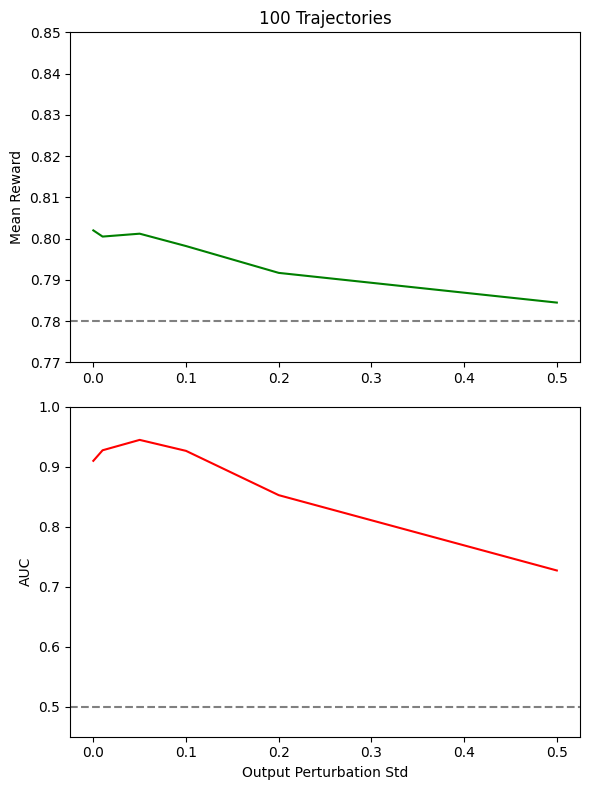

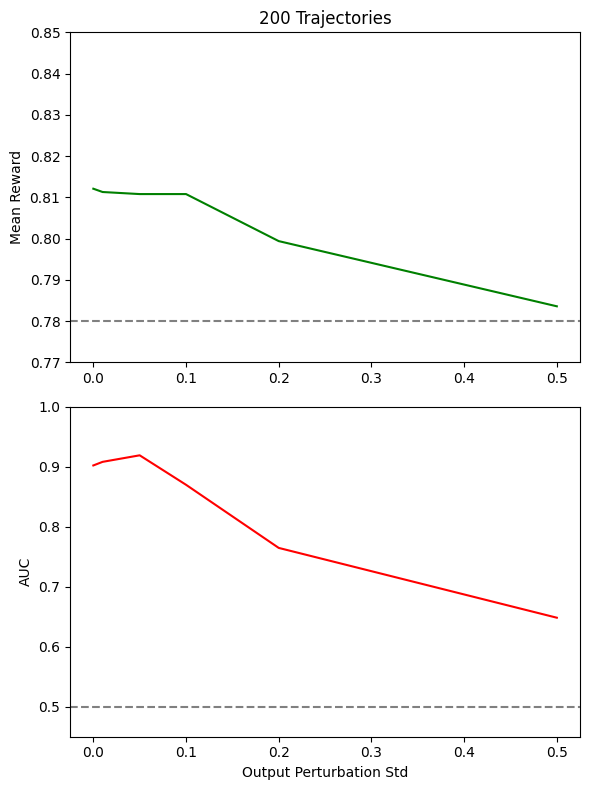

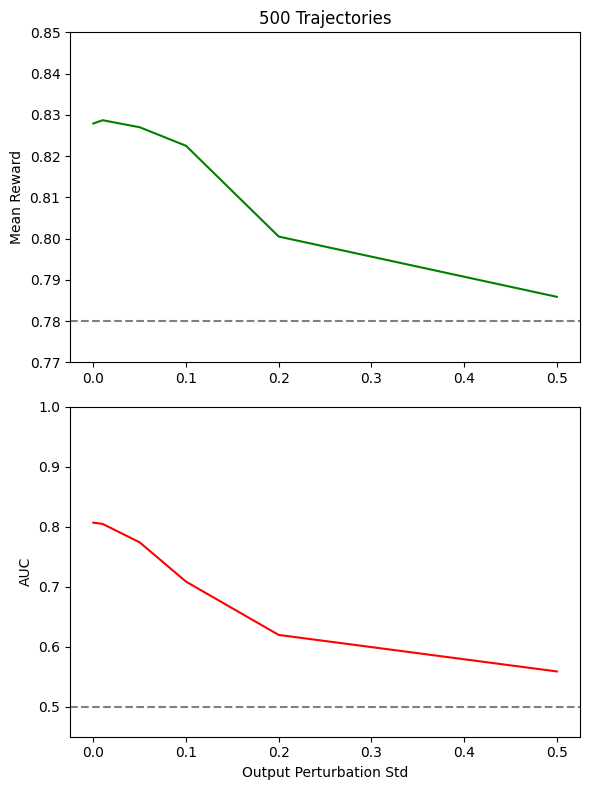

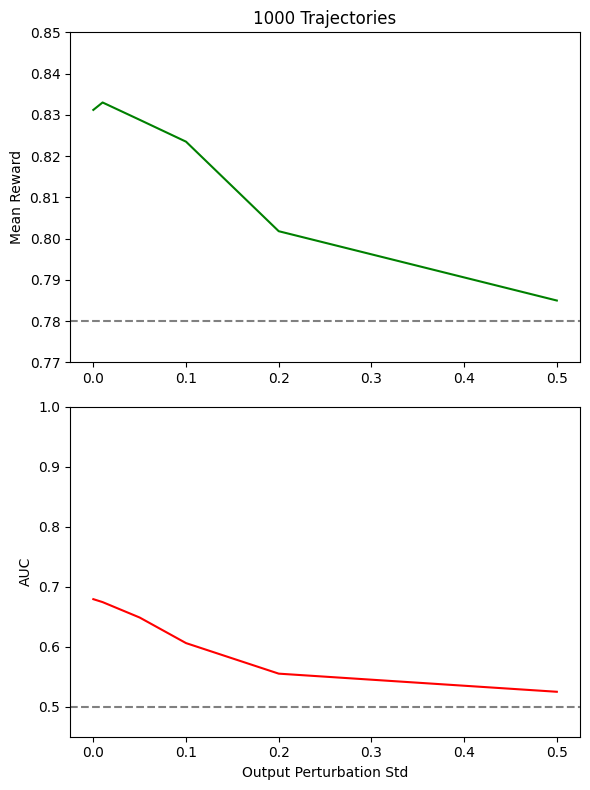

In [6]:
# Plot reward vs perturbation std for particular n. trajs
n_trajs = df_clean["N. Trajectories"].unique()

for n_traj in n_trajs:
    group = df_clean[df_clean["N. Trajectories"] == n_traj]
    
    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(6, 8))
    
    # Rewards
    ax1.plot(group["Output Perturbation std"], group["Trainer Mean Reward (mean)"], color="green")
    ax1.set_ylim([0.77, 0.85])
    ax1.set_ylabel("Mean Reward")
    ax1.axhline(0.78, color="gray", linestyle="--")
    ax1.set_title(f"{n_traj} Trajectories")
    
    # Rewards
    ax2.plot(group["Output Perturbation std"], group["AUC (mean)"], color="red")
    ax2.set_ylim([0.45, 1.0])
    ax2.set_xlabel("Output Perturbation Std")
    ax2.set_ylabel("AUC")
    ax2.axhline(0.5, color="gray", linestyle="--")

    plt.tight_layout()
    plt.show()

    

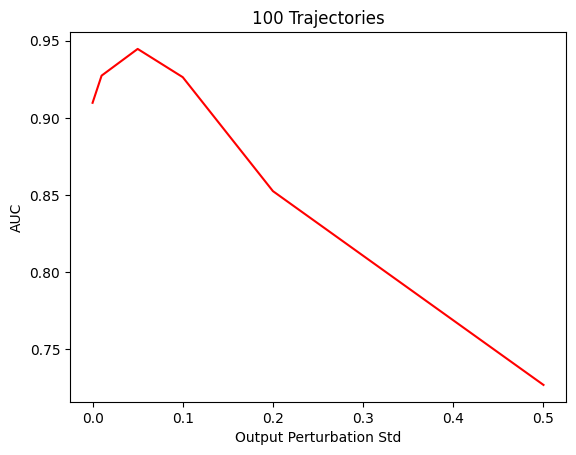

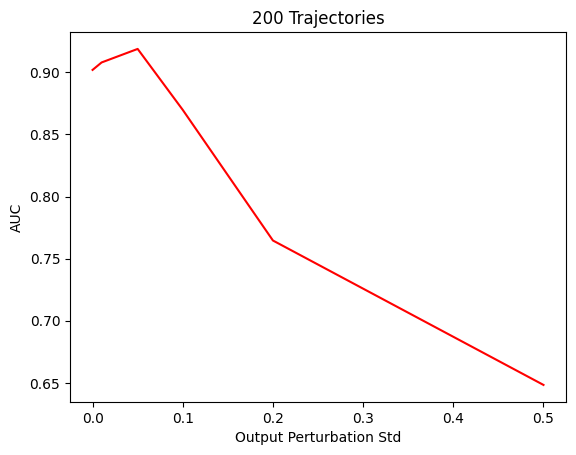

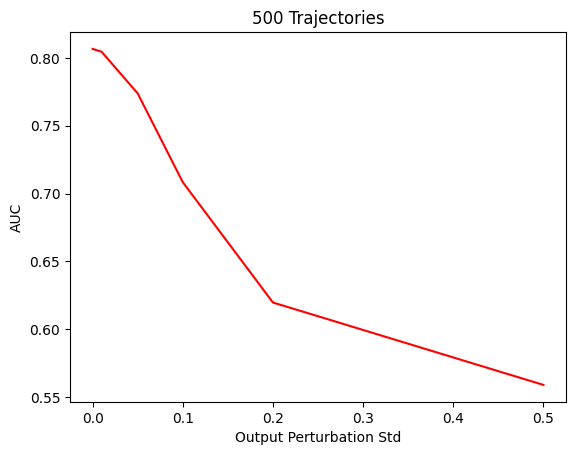

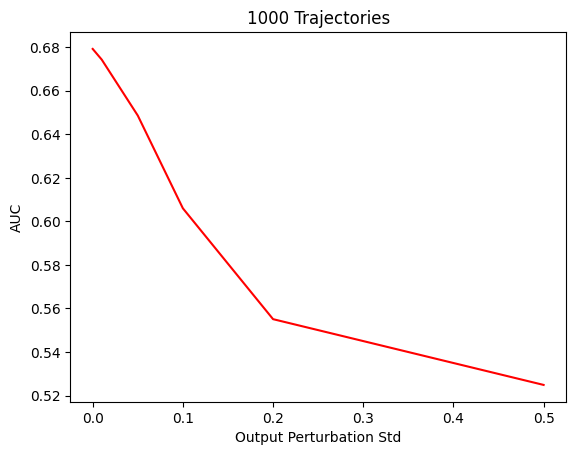

In [7]:
for n_traj in n_trajs:
    group = df_clean[df_clean["N. Trajectories"] == n_traj]
    plt.plot(group["Output Perturbation std"], group["AUC (mean)"], color="red")
    plt.xlabel("Output Perturbation Std")
    plt.ylabel("AUC")
    plt.title(f"{n_traj} Trajectories")
    plt.show()